# Notebook 02: Model Experiments, Cross-Validation & Feature Ablation
**Project:** Water Potability & Underwater Environmental Monitoring  
**Cadre:** Acyntra AIML Intern Cadre (Group C1)  
**Objective:** Execute Stratified 5-Fold Cross Validation without leakage, benchmark WHO rules vs. Linear vs. Tree ensembles, calibrate probabilities, and conduct Leave-One-Feature-Out (LOFO) ablation.

In [1]:
import os
import sys
from pathlib import Path

project_root = Path("..").resolve() if Path("..").resolve().name == "Water Potability" else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.pipeline.runner import ExperimentRunner
from src.pipeline.ablation import FeatureAblationEngine
from src.data.loader import DataLoader
from src.features.engineer import FeatureEngineer

print("Environment initialized for Model Experiments. Root:", project_root)

Environment initialized for Model Experiments. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Cross-Validation Leaderboard & Single-Pass Lockbox Evaluation

In [2]:
runner = ExperimentRunner("configs/track_b_tabular.yaml")
results = runner.run_track_b_experiments()

print("\n=== MODEL BENCHMARK LEADERBOARD ===")
print("Champion Candidate Architecture:", results["best_model"])
print("Lockbox Test Set Metrics:", results["lockbox_metrics"])
results["leaderboard"]

2026-10-18 09:02:27 | INFO     | ExperimentRunner:45 - Deterministic seed pinned to 42
2026-10-18 09:02:27 | INFO     | DataLoader:124 - Successfully loaded 3276 rows and 10 columns from data\01_raw\water_potability.csv
2026-10-18 09:02:27 | INFO     | ExperimentRunner:72 - Loaded Track B dataset: (3276, 10)
2026-10-18 09:02:27 | INFO     | FeatureEngineer:52 - Engineered Track B features: Shape evolved from (3276, 10) to (3276, 19)
2026-10-18 09:02:27 | INFO     | DataPreprocessor:124 - Track B Split complete: Train=2620 (Positive=39.01%), Test Lockbox=656 (Positive=39.02%)
2026-10-18 09:02:27 | INFO     | ExperimentRunner:100 - Evaluating WHO_Baseline on 5-Fold Stratified CV (Dev Set with fold-internal fitting)...
2026-10-18 09:02:42 | INFO     | ExperimentRunner:100 - Evaluating Logistic_Regression on 5-Fold Stratified CV (Dev Set with fold-internal fitting)...
2026-10-18 09:02:44 | INFO     | ExperimentRunner:100 - Evaluating Random_Forest on 5-Fold Stratified CV (Dev Set with fold

,model_name,cv_pr_auc_mean,cv_f1_mean,cv_brier_mean
0,WHO_Baseline,0.4192,0.0000,0.2434
1,Logistic_Regression,0.4329,0.4778,0.2492
2,Random_Forest,0.5556,0.4955,0.2307
3,XGBoost,0.5793,0.5132,0.2223


## 2. Cross-Validation Metric Comparison Bar Chart

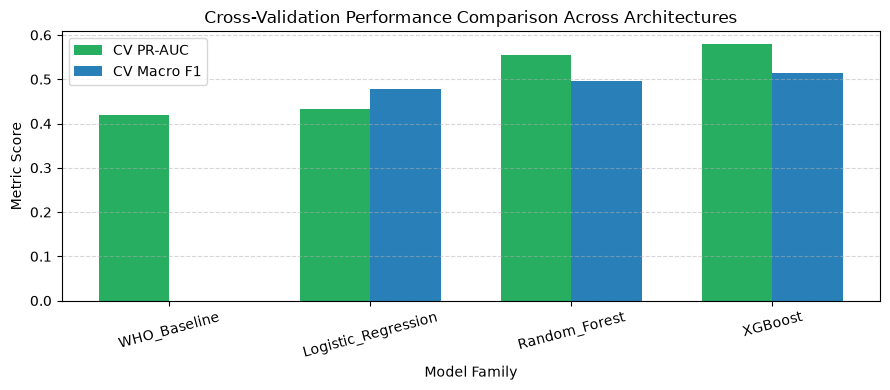

In [3]:
df_lead = results["leaderboard"]
plt.figure(figsize=(9, 4))
x = np.arange(len(df_lead))
width = 0.35

plt.bar(x - width/2, df_lead["cv_pr_auc_mean"], width, label="CV PR-AUC", color="#27ae60")
plt.bar(x + width/2, df_lead["cv_f1_mean"], width, label="CV Macro F1", color="#2980b9")

plt.xlabel("Model Family")
plt.ylabel("Metric Score")
plt.title("Cross-Validation Performance Comparison Across Architectures")
plt.xticks(x, df_lead["model_name"], rotation=15)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 3. Systematic Feature & Sensor Ablation Study (LOFO)

In [4]:
df, _, _ = DataLoader.load_dataset("data/01_raw/water_potability.csv", force_track="B")
df_fe = FeatureEngineer.engineer_track_b_features(df)
X = df_fe.drop(columns=["Potability"])
y = df_fe["Potability"]

ablation = FeatureAblationEngine(random_state=42)
base_raw_features = list(X.columns)[:9]
ablation_df = ablation.run_tabular_ablation(X, y, base_features=base_raw_features)
ablation_df

2026-10-18 09:03:36 | INFO     | DataLoader:124 - Successfully loaded 3276 rows and 10 columns from data\01_raw\water_potability.csv
2026-10-18 09:03:36 | INFO     | FeatureEngineer:52 - Engineered Track B features: Shape evolved from (3276, 10) to (3276, 19)
2026-10-18 09:03:44 | INFO     | FeatureAblationEngine:50 - Baseline PR-AUC with all 9 features: 0.5962
2026-10-18 09:03:51 | INFO     | FeatureAblationEngine:63 - Ablation [-ph]: PR-AUC=0.5006 (Delta=-0.0957)
2026-10-18 09:03:57 | INFO     | FeatureAblationEngine:63 - Ablation [-Hardness]: PR-AUC=0.5740 (Delta=-0.0223)
2026-10-18 09:04:04 | INFO     | FeatureAblationEngine:63 - Ablation [-Solids]: PR-AUC=0.5703 (Delta=-0.0259)
2026-10-18 09:04:18 | INFO     | FeatureAblationEngine:63 - Ablation [-Chloramines]: PR-AUC=0.5671 (Delta=-0.0291)
2026-10-18 09:04:28 | INFO     | FeatureAblationEngine:63 - Ablation [-Sulfate]: PR-AUC=0.4961 (Delta=-0.1001)
2026-10-18 09:04:38 | INFO     | FeatureAblationEngine:63 - Ablation [-Conductivit

,ablated_feature,pr_auc,delta_pr_auc
5,Sulfate,0.49610,-0.1001
1,ph,0.50060,-0.0957
4,Chloramines,0.56710,-0.0291
3,Solids,0.57030,-0.0259
2,Hardness,0.57400,-0.0223
0,NONE (Full Baseline),0.59624,0.0000
7,Organic_carbon,0.59930,0.0030
6,Conductivity,0.60140,0.0051
8,Trihalomethanes,0.60230,0.0060
9,Turbidity,0.60930,0.0131


## 4. Feature Ablation Sensitivity Plot

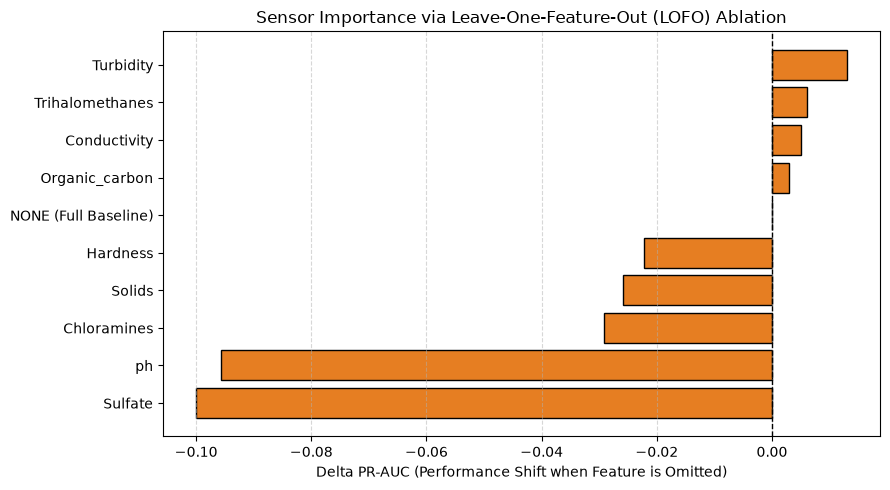

In [5]:
plt.figure(figsize=(9, 5))
bars = plt.barh(ablation_df["ablated_feature"], ablation_df["delta_pr_auc"], color="#e67e22", edgecolor="black")
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Delta PR-AUC (Performance Shift when Feature is Omitted)")
plt.title("Sensor Importance via Leave-One-Feature-Out (LOFO) Ablation")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()